In [2]:
#package installation
!pip install -q numpy==2.2.6 pandas==2.2.3 matplotlib==3.11.2 seaborn==0.13.2 scikit-learn==1.9.1 sentence-transformers==6.1.0 fastapi==0.141.1 joblib==1.6.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 87.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 109.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 55.0 MB/s eta 0:00:00


In [2]:
import os
import math
import random
import zipfile
import urllib.request
import warnings
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sentence_transformers

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

# use one seed so that the experiment can be reproduced
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"The model will train with: {device}")

The model will train with: cuda


## Download and Load the MovieLens 100K dataset

In [3]:

# define the download and extraction locations
data_folder = Path("data")
dataset_folder = data_folder / "ml-100k"
zip_path = data_folder / "ml-100k.zip"
dataset_url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

# create the data folder
data_folder.mkdir(exist_ok=True)

# download the MovieLens 100K dataset
urllib.request.urlretrieve(dataset_url, zip_path)

# extract the downloaded dataset
with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall(data_folder)

print("MovieLens 100K was downloaded and extracted successfully.")

MovieLens 100K was downloaded and extracted successfully.


In [4]:
# column names that were given in the official MovieLens README
rating_columns = ["user_id", "movie_id", "rating", "timestamp"]
user_columns = ["user_id", "age", "gender", "occupation", "zip_code"]
genre_columns = [ "unknown", "Action", "Adventure", "Animation", "Children", "Comedy", "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western" ]
movie_columns = [ "movie_id", "title", "release_date", "video_release_date", "imdb_url" ] + genre_columns

# load the three tables
ratings_df = pd.read_csv( dataset_folder / "u.data", sep="\t", names=rating_columns )
movies_df = pd.read_csv( dataset_folder / "u.item", sep="|", names=movie_columns, encoding="latin-1" )
users_df = pd.read_csv( dataset_folder / "u.user", sep="|", names=user_columns )

print(ratings_df.head())
print(f"\nNumber of ratings: {len(ratings_df):,}")
print(f"Number of users: {ratings_df['user_id'].nunique():,}")
print(f"Number of movies: {ratings_df['movie_id'].nunique():,}")

   user_id  movie_id  rating  timestamp
0      196       242       3  881250949
1      186       302       3  891717742
2       22       377       1  878887116
3      244        51       2  880606923
4      166       346       1  886397596

Number of ratings: 100,000
Number of users: 943
Number of movies: 1,682


In [5]:
# confirm that the dataset has the expected official sizes
assert len(ratings_df) == 100000, "The ratings file should contain 100,000 rows."
assert ratings_df["user_id"].nunique() == 943, "The dataset should contain 943 users."
assert ratings_df["movie_id"].nunique() == 1682, "The dataset should contain 1,682 movies."
assert ratings_df["rating"].between(1, 5).all(), "Every rating should be between 1 and 5."

# convert the Unix timestamp into a readable date
ratings_df["rating_date"] = pd.to_datetime(ratings_df["timestamp"], unit="s")

# combine the genre flags into one readable genre string
def getMovieGenres(row):
    selected_genres = []

    for genre in genre_columns:
        if row[genre] == 1:
            selected_genres.append(genre)

    return "|".join(selected_genres)


movies_df["genres"] = movies_df.apply(getMovieGenres, axis=1)
movies_df[["movie_id", "title", "genres"]].head()

,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children|Comedy
1,2,GoldenEye (1995),Action|Adventure|Thriller
2,3,Four Rooms (1995),Thriller
3,4,Get Shorty (1995),Action|Comedy|Drama
4,5,Copycat (1995),Crime|Drama|Thriller


## Separate the data into Train, Validation and Test Split according to chronological order

In [6]:
# function that hides the two most recent ratings from every user
def chronologicalSplit(ratings_df):
    sorted_ratings = ratings_df.sort_values(["user_id", "timestamp"]).copy()

    # obtain the position of each rating inside a user's history
    sorted_ratings["position"] = sorted_ratings.groupby("user_id").cumcount()
    sorted_ratings["history_size"] = sorted_ratings.groupby("user_id")["movie_id"].transform("size")

    test_df = sorted_ratings[ sorted_ratings["position"] == sorted_ratings["history_size"] - 1 ].copy()

    validation_df = sorted_ratings[ sorted_ratings["position"] == sorted_ratings["history_size"] - 2 ].copy()

    train_df = sorted_ratings[ sorted_ratings["position"] < sorted_ratings["history_size"] - 2 ].copy()

    columns_to_remove = ["position", "history_size"]
    train_df = train_df.drop(columns=columns_to_remove)
    validation_df = validation_df.drop(columns=columns_to_remove)
    test_df = test_df.drop(columns=columns_to_remove)

    return train_df, validation_df, test_df


train_df, validation_df, test_df = chronologicalSplit(ratings_df)

print(f"Training ratings: {len(train_df):,}")
print(f"Validation ratings: {len(validation_df):,}")
print(f"Test ratings: {len(test_df):,}")

Training ratings: 98,114
Validation ratings: 943
Test ratings: 943


In [7]:
# a check that ensures the data is in the right order of train -> validation -> test.
train_last_time = train_df.groupby("user_id")["timestamp"].max()
validation_time = validation_df.set_index("user_id")["timestamp"]
test_time = test_df.set_index("user_id")["timestamp"]

assert (train_last_time <= validation_time).all(), "Training must occur before validation."
assert (validation_time <= test_time).all(), "Validation must occur before testing."
print("The chronological split passed all checks.")

The chronological split passed all checks.


In [8]:
# create continuous zero-based IDs for PyTorch embedding tables
user_ids = sorted(ratings_df["user_id"].unique())
movie_ids = sorted(ratings_df["movie_id"].unique())

user_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
movie_to_index = {movie_id: index for index, movie_id in enumerate(movie_ids)}
index_to_movie = {index: movie_id for movie_id, index in movie_to_index.items()}

number_of_users = len(user_to_index)
number_of_movies = len(movie_to_index)

for dataframe in [train_df, validation_df, test_df]:
    dataframe["user_index"] = dataframe["user_id"].map(user_to_index)
    dataframe["movie_index"] = dataframe["movie_id"].map(movie_to_index)

print(f"User embedding rows: {number_of_users}")
print(f"Movie embedding rows: {number_of_movies}")

User embedding rows: 943
Movie embedding rows: 1682


## A. The popularity recommender

In [9]:
# function that applies Bayesian shrinkage to movie average ratings
def calculatePopularityScores(train_df, minimum_votes=20):
    global_average = train_df["rating"].mean()
    movie_summary = train_df.groupby("movie_index")["rating"].agg(["mean", "count"])

    movie_summary["score"] = ( (movie_summary["count"] / (movie_summary["count"] + minimum_votes)) * movie_summary["mean"] + (minimum_votes / (movie_summary["count"] + minimum_votes)) * global_average )

    scores = np.full(number_of_movies, global_average, dtype=np.float32)
    scores[movie_summary.index] = movie_summary["score"].values
    return scores


popularity_scores = calculatePopularityScores(train_df)

top_popular_indexes = np.argsort(popularity_scores)[::-1][:10]
top_popular_ids = [index_to_movie[index] for index in top_popular_indexes]

movies_df[movies_df["movie_id"].isin(top_popular_ids)][ ["movie_id", "title", "genres"] ].head(10)

,movie_id,title,genres
11,12,"Usual Suspects, The (1995)",Crime|Thriller
49,50,Star Wars (1977),Action|Adventure|Romance|Sci-Fi|War
63,64,"Shawshank Redemption, The (1994)",Drama
97,98,"Silence of the Lambs, The (1991)",Drama|Thriller
126,127,"Godfather, The (1972)",Action|Crime|Drama
168,169,"Wrong Trousers, The (1993)",Animation|Comedy
317,318,Schindler's List (1993),Drama|War
407,408,"Close Shave, A (1995)",Animation|Comedy|Thriller
482,483,Casablanca (1942),Drama|Romance|War
602,603,Rear Window (1954),Mystery|Thriller


## B. Biased Matrix Factorization model

In [10]:
# dataset that returns one user, one movie and the rating given
class RatingDataset(Dataset):
    def __init__(self, dataframe):
        self.user_indexes = torch.tensor(dataframe["user_index"].values, dtype=torch.long)
        self.movie_indexes = torch.tensor(dataframe["movie_index"].values, dtype=torch.long)
        self.ratings = torch.tensor(dataframe["rating"].values, dtype=torch.float32)

    def __len__(self):
        return len(self.ratings)

    def __getitem__(self, index):
        return self.user_indexes[index], self.movie_indexes[index], self.ratings[index]


# matrix factorization model with global, user and movie biases
class MatrixFactorization(nn.Module):
    def __init__(self, number_of_users, number_of_movies, embedding_size=64):
        super().__init__()
        self.user_embedding = nn.Embedding(number_of_users, embedding_size)
        self.movie_embedding = nn.Embedding(number_of_movies, embedding_size)
        self.user_bias = nn.Embedding(number_of_users, 1)
        self.movie_bias = nn.Embedding(number_of_movies, 1)
        self.global_average = nn.Parameter(torch.tensor(train_df["rating"].mean()))

        nn.init.normal_(self.user_embedding.weight, std=0.05)
        nn.init.normal_(self.movie_embedding.weight, std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, user_indexes, movie_indexes):
        user_vectors = self.user_embedding(user_indexes)
        movie_vectors = self.movie_embedding(movie_indexes)

        interaction = (user_vectors * movie_vectors).sum(dim=1)
        user_bias = self.user_bias(user_indexes).squeeze(1)
        movie_bias = self.movie_bias(movie_indexes).squeeze(1)

        return self.global_average + user_bias + movie_bias + interaction

In [11]:
# function that trains any explicit-rating model
def trainRatingModel(model, train_loader, validation_loader, epochs=8, learning_rate=0.002):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-5)
    loss_function = nn.MSELoss()
    training_history = []

    for epoch in range(epochs):
        model.train()
        total_training_loss = 0

        for user_indexes, movie_indexes, ratings in train_loader:
            user_indexes = user_indexes.to(device)
            movie_indexes = movie_indexes.to(device)
            ratings = ratings.to(device)

            predictions = model(user_indexes, movie_indexes)
            loss = loss_function(predictions, ratings)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_training_loss += loss.item() * len(ratings)

        model.eval()
        total_validation_squared_error = 0
        validation_count = 0

        with torch.no_grad():
            for user_indexes, movie_indexes, ratings in validation_loader:
                user_indexes = user_indexes.to(device)
                movie_indexes = movie_indexes.to(device)
                ratings = ratings.to(device)

                predictions = model(user_indexes, movie_indexes)
                total_validation_squared_error += ((predictions - ratings) ** 2).sum().item()
                validation_count += len(ratings)

        training_loss = total_training_loss / len(train_loader.dataset)
        validation_rmse = math.sqrt(total_validation_squared_error / validation_count)
        training_history.append([epoch + 1, training_loss, validation_rmse])

        print( f"Epoch {epoch + 1}/{epochs} - " f"training loss: {training_loss:.4f} - validation RMSE: {validation_rmse:.4f}" )

    return pd.DataFrame( training_history, columns=["epoch", "training_loss", "validation_rmse"] )

In [12]:
# build the data loaders
BATCH_SIZE = 512
train_dataset = RatingDataset(train_df)
validation_dataset = RatingDataset(validation_df)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)

# train the matrix factorization model
matrix_model = MatrixFactorization( number_of_users, number_of_movies, embedding_size=64 ).to(device)

matrix_history = trainRatingModel( matrix_model, train_loader, validation_loader, epochs=8, learning_rate=0.002 )

Epoch 1/8 - training loss: 1.1775 - validation RMSE: 1.1219
Epoch 2/8 - training loss: 0.9456 - validation RMSE: 1.0373
Epoch 3/8 - training loss: 0.7388 - validation RMSE: 0.9923
Epoch 4/8 - training loss: 0.5928 - validation RMSE: 0.9810
Epoch 5/8 - training loss: 0.4753 - validation RMSE: 0.9838
Epoch 6/8 - training loss: 0.3831 - validation RMSE: 0.9932
Epoch 7/8 - training loss: 0.3149 - validation RMSE: 1.0086
Epoch 8/8 - training loss: 0.2654 - validation RMSE: 1.0216


## C. Neural Collaborative Filtering model

In [13]:
# neural model that learns nonlinear relationships between users and movies
class NeuralCollaborativeFiltering(nn.Module):
    def __init__(self, number_of_users, number_of_movies, embedding_size=48):
        super().__init__()
        self.user_embedding = nn.Embedding(number_of_users, embedding_size)
        self.movie_embedding = nn.Embedding(number_of_movies, embedding_size)

        self.layers = nn.Sequential( nn.Linear(embedding_size * 2, 128), nn.ReLU(), nn.Dropout(0.20), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.10), nn.Linear(64, 1) )

    def forward(self, user_indexes, movie_indexes):
        user_vectors = self.user_embedding(user_indexes)
        movie_vectors = self.movie_embedding(movie_indexes)
        combined_vectors = torch.cat([user_vectors, movie_vectors], dim=1)
        return self.layers(combined_vectors).squeeze(1)


neural_model = NeuralCollaborativeFiltering( number_of_users, number_of_movies ).to(device)

neural_history = trainRatingModel( neural_model, train_loader, validation_loader, epochs=8, learning_rate=0.001 )

Epoch 1/8 - training loss: 2.2745 - validation RMSE: 1.1425
Epoch 2/8 - training loss: 1.1762 - validation RMSE: 1.1004
Epoch 3/8 - training loss: 1.0904 - validation RMSE: 1.0712
Epoch 4/8 - training loss: 1.0433 - validation RMSE: 1.0559
Epoch 5/8 - training loss: 1.0086 - validation RMSE: 1.0370
Epoch 6/8 - training loss: 0.9834 - validation RMSE: 1.0339
Epoch 7/8 - training loss: 0.9660 - validation RMSE: 1.0189
Epoch 8/8 - training loss: 0.9491 - validation RMSE: 1.0148


## D. Hugging Face Content Model
Build Movie Content Embeddings Using a Pretrained Sentence Transformer

In [14]:
# build a short text description from information available in MovieLens
movies_df["content_text"] = ( movies_df["title"].fillna("") + ". Genres: " + movies_df["genres"].str.replace("|", ", ", regex=False).fillna("") )


# function that uses Hugging Face to build movie content embeddings
def buildContentEmbeddings(movies_df):
    # arrange the movies in the same order used by the recommendation models
    ordered_movies = movies_df.set_index("movie_id").reindex(movie_ids)

    # convert every movie title and genre into one text value
    movie_texts = ordered_movies["content_text"].fillna("").tolist()

    from sentence_transformers import SentenceTransformer

    print("Downloading or loading the Hugging Face model...")

    # download the model or load it from the local cache
    content_model = SentenceTransformer( "sentence-transformers/all-MiniLM-L6-v2" )

    # convert every movie text into an embedding
    content_embeddings = content_model.encode( movie_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True )

    # convert the embeddings into a NumPy array
    content_embeddings = np.asarray( content_embeddings, dtype=np.float32 )

    content_method = "Hugging Face all-MiniLM-L6-v2"

    # confirm that all movies received a 384-dimensional embedding
    assert content_embeddings.shape == ( number_of_movies, 384 ), "Unexpected content embedding shape."

    # confirm that the embeddings do not contain invalid values
    assert np.isfinite(content_embeddings).all(), ( "The embeddings contain invalid values." )

    print("Hugging Face model loaded successfully.")
    print(f"Content method: {content_method}")
    print(f"Embedding shape: {content_embeddings.shape}")

    return content_embeddings, content_model, content_method


# build the movie content embeddings
content_embeddings, content_model, content_method = ( buildContentEmbeddings(movies_df) )

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/27 [00:00<?, ?it/s]

Hugging Face model loaded successfully.
Content method: Hugging Face all-MiniLM-L6-v2
Embedding shape: (1682, 384)


In [15]:
# function that finds movies with similar text and genre content
def findSimilarMovies(movie_id, number_of_results=10):
    movie_index = movie_to_index[movie_id]
    similarities = cosine_similarity( content_embeddings[movie_index].reshape(1, -1), content_embeddings )[0]

    similar_indexes = np.argsort(similarities)[::-1]
    similar_indexes = [index for index in similar_indexes if index != movie_index]
    similar_indexes = similar_indexes[:number_of_results]

    results = []
    for index in similar_indexes:
        selected_movie_id = index_to_movie[index]
        movie_information = movies_df[movies_df["movie_id"] == selected_movie_id].iloc[0]
        results.append({ "movie_id": selected_movie_id, "title": movie_information["title"], "genres": movie_information["genres"], "similarity": float(similarities[index]) })

    return pd.DataFrame(results)


# example: find movies similar to Toy Story
findSimilarMovies(movie_id=1, number_of_results=10)

,movie_id,title,genres,similarity
0,1219,"Goofy Movie, A (1995)",Animation|Children|Comedy|Romance,0.781928
1,1470,Gumby: The Movie (1995),Animation|Children,0.743310
2,772,Kids (1995),Drama,0.705806
3,8,Babe (1995),Children|Comedy|Drama,0.698879
4,1063,"Little Princess, A (1995)",Children|Drama,0.689943
5,993,Hercules (1997),Adventure|Animation|Children|Comedy|Musical,0.689633
6,1409,"Swan Princess, The (1994)",Animation|Children,0.687105
7,820,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy,0.686825
8,932,First Kid (1996),Children|Comedy,0.675464
9,473,James and the Giant Peach (1996),Animation|Children|Musical,0.675166


## E. Sequential Transformer Recommender

The transformer treats a user's positively rated movie history as an ordered sequence. Movies are the tokens, and the model learns which earlier choices help predict a later choice.

Only ratings of 4 or 5 are treated as positive interactions for this model. Zero is reserved for padding, so each real movie index is shifted by one.

In [16]:
# create chronological sequences containing movies each user liked
def buildPositiveSequences(train_df, minimum_rating=4):
    positive_ratings = train_df[train_df["rating"] >= minimum_rating]
    positive_ratings = positive_ratings.sort_values(["user_id", "timestamp"])

    sequences = {}
    for user_id, user_data in positive_ratings.groupby("user_id"):
        # add one because zero is used for padding
        sequences[user_to_index[user_id]] = (user_data["movie_index"] + 1).tolist()

    return sequences


positive_sequences = buildPositiveSequences(train_df)
sequence_lengths = [len(sequence) for sequence in positive_sequences.values()]

print(f"Users with positive training sequences: {len(positive_sequences)}")
print(f"Median positive sequence length: {np.median(sequence_lengths):.0f}")

Users with positive training sequences: 942
Median positive sequence length: 38


In [17]:
# dataset that creates next-movie examples from every positive sequence
class SequenceDataset(Dataset):
    def __init__(self, sequences, maximum_length=50):
        self.examples = []
        self.maximum_length = maximum_length

        for user_index, sequence in sequences.items():
            if len(sequence) < 2:
                continue

            for target_position in range(1, len(sequence)):
                history = sequence[max(0, target_position - maximum_length):target_position]
                target = sequence[target_position]
                self.examples.append([user_index, history, target])

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        user_index, history, target = self.examples[index]
        padded_history = [0] * (self.maximum_length - len(history)) + history

        return ( torch.tensor(user_index, dtype=torch.long), torch.tensor(padded_history, dtype=torch.long), torch.tensor(target, dtype=torch.long) )


class SequentialTransformer(nn.Module):
    def __init__(self, number_of_movies, maximum_length=50, embedding_size=64):
        super().__init__()
        self.maximum_length = maximum_length
        self.movie_embedding = nn.Embedding(number_of_movies + 1, embedding_size, padding_idx=0)
        self.position_embedding = nn.Embedding(maximum_length, embedding_size)

        transformer_layer = nn.TransformerEncoderLayer( d_model=embedding_size, nhead=4, dim_feedforward=embedding_size * 4, dropout=0.15, batch_first=True, norm_first=True )

        self.transformer = nn.TransformerEncoder(transformer_layer, num_layers=2)
        self.layer_norm = nn.LayerNorm(embedding_size)

    def forward(self, movie_sequences):
        batch_size, sequence_length = movie_sequences.shape
        positions = torch.arange(sequence_length, device=movie_sequences.device)

        x = self.movie_embedding(movie_sequences)
        x = x + self.position_embedding(positions).unsqueeze(0)

        padding_mask = movie_sequences == 0
        causal_mask = torch.triu( torch.ones(sequence_length, sequence_length, device=movie_sequences.device), diagonal=1 ).bool()

        x = self.transformer( x, mask=causal_mask, src_key_padding_mask=padding_mask )

        x = self.layer_norm(x)
        return x[:, -1, :]

    def scoreAllMovies(self, movie_sequences):
        user_vectors = self.forward(movie_sequences)
        movie_vectors = self.movie_embedding.weight[1:]
        return user_vectors @ movie_vectors.T

In [18]:
import copy

# function that evaluates the transformer on the validation data
def evaluateSequentialValidation( model, positive_sequences, validation_df, maximum_length=50, k=10 ):
    model.eval()
    hit_scores = []
    ndcg_scores = []

    # use only movies that received a positive rating
    relevant_validation = validation_df[ validation_df["rating"] >= 4 ]

    with torch.no_grad():
        for _, row in relevant_validation.iterrows():
            user_index = int(row["user_index"])
            validation_movie_index = int(row["movie_index"])

            user_sequence = positive_sequences.get( user_index, [] )

            if len(user_sequence) == 0:
                continue

            # keep only the most recent movies
            user_sequence = user_sequence[ -maximum_length: ]

            # add padding to the beginning of the sequence
            padded_sequence = ( [0] * ( maximum_length - len(user_sequence) ) + user_sequence )

            sequence_tensor = torch.tensor( [padded_sequence], dtype=torch.long, device=device )

            # calculate a score for every movie
            scores = model.scoreAllMovies( sequence_tensor )[0]

            scores = scores.cpu().numpy()

            # remove movies already present in the user's history
            for shifted_movie_index in user_sequence:
                movie_index = shifted_movie_index - 1
                scores[movie_index] = -np.inf

            # obtain the top-k recommended movies
            top_movie_indexes = np.argsort( scores )[::-1][:k]

            if validation_movie_index in top_movie_indexes:
                rank = ( np.where( top_movie_indexes == validation_movie_index )[0][0] + 1 )

                hit_scores.append(1)

                ndcg_scores.append( 1 / math.log2(rank + 1) )

            else:
                hit_scores.append(0)
                ndcg_scores.append(0)

    validation_hit_rate = np.mean(hit_scores)
    validation_ndcg = np.mean(ndcg_scores)

    return validation_hit_rate, validation_ndcg

# function that trains the transformer and stops when validation stops improving
def trainSequentialModel(model, data_loader, positive_sequences, validation_df, maximum_length=50, epochs=20, learning_rate=0.001, patience=3):
    optimizer = torch.optim.AdamW( model.parameters(), lr=learning_rate, weight_decay=1e-5 )

    loss_function = nn.CrossEntropyLoss()

    best_validation_ndcg = -1
    best_model_state = None
    epochs_without_improvement = 0
    training_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for user_indexes, histories, targets in data_loader:
            histories = histories.to(device)

            # subtract one because transformer targets contain a padding offset
            targets = (targets - 1).to(device)

            scores = model.scoreAllMovies(histories)

            loss = loss_function( scores, targets )

            optimizer.zero_grad()
            loss.backward()

            # prevent extremely large gradients
            torch.nn.utils.clip_grad_norm_( model.parameters(), max_norm=1.0 )

            optimizer.step()

            total_loss += ( loss.item() * len(targets) )

        average_loss = ( total_loss / len(data_loader.dataset) )

        validation_hit_rate, validation_ndcg = ( evaluateSequentialValidation( model, positive_sequences, validation_df, maximum_length=maximum_length, k=10 ) )

        training_history.append({ "epoch": epoch + 1, "training_loss": average_loss, "validation_hit_rate@10": validation_hit_rate, "validation_ndcg@10": validation_ndcg })

        print( f"Epoch {epoch + 1}/{epochs} - " f"training loss: {average_loss:.4f} - " f"validation Hit Rate@10: " f"{validation_hit_rate:.4f} - " f"validation NDCG@10: " f"{validation_ndcg:.4f}" )

        # save the model when validation performance improves
        if validation_ndcg > best_validation_ndcg:
            best_validation_ndcg = validation_ndcg
            best_model_state = copy.deepcopy( model.state_dict() )
            epochs_without_improvement = 0

            print("The best transformer model was updated.")

        else:
            epochs_without_improvement += 1

            print( f"No validation improvement for " f"{epochs_without_improvement} epoch(s)." )

        # stop when validation has not improved for several epochs
        if epochs_without_improvement >= patience:
            print("Early stopping was activated.")
            break

    # restore the model with the best validation performance
    if best_model_state is not None:
        model.load_state_dict( best_model_state )

    print( f"Best validation NDCG@10: " f"{best_validation_ndcg:.4f}" )

    return pd.DataFrame(training_history)

In [19]:
MAXIMUM_SEQUENCE_LENGTH = 50

# create the sequential training dataset
sequence_dataset = SequenceDataset( positive_sequences, MAXIMUM_SEQUENCE_LENGTH )

# load the sequence data in batches
sequence_loader = DataLoader( sequence_dataset, batch_size=256, shuffle=True )

# create the transformer model
sequential_model = SequentialTransformer( number_of_movies, maximum_length=MAXIMUM_SEQUENCE_LENGTH, embedding_size=64 ).to(device)

print(f"Number of training examples: {len(sequence_dataset):,}")
print(f"Number of batches per epoch: {len(sequence_loader):,}")
print(f"Training device: {device}")
print("Starting sequential transformer training...\n")

# train the transformer
sequential_history = trainSequentialModel( sequential_model, sequence_loader, positive_sequences, validation_df, maximum_length=MAXIMUM_SEQUENCE_LENGTH, epochs=20, learning_rate=0.001, patience=3 )

print("\nTraining completed.")
print(sequential_history)

Number of training examples: 53,454
Number of batches per epoch: 209
Training device: cuda
Starting sequential transformer training...

Epoch 1/20 - training loss: 13.2165 - validation Hit Rate@10: 0.0122 - validation NDCG@10: 0.0046
The best transformer model was updated.
Epoch 2/20 - training loss: 7.5036 - validation Hit Rate@10: 0.0203 - validation NDCG@10: 0.0088
The best transformer model was updated.
Epoch 3/20 - training loss: 6.9678 - validation Hit Rate@10: 0.0223 - validation NDCG@10: 0.0122
The best transformer model was updated.
Epoch 4/20 - training loss: 6.7458 - validation Hit Rate@10: 0.0162 - validation NDCG@10: 0.0068
No validation improvement for 1 epoch(s).
Epoch 5/20 - training loss: 6.5811 - validation Hit Rate@10: 0.0162 - validation NDCG@10: 0.0082
No validation improvement for 2 epoch(s).
Epoch 6/20 - training loss: 6.4572 - validation Hit Rate@10: 0.0203 - validation NDCG@10: 0.0097
No validation improvement for 3 epoch(s).
Early stopping was activated.
Best 

Functions that calculates scores for every model

In [20]:
# when predicting the final test interaction, training and validation interactions are already known
inference_df = pd.concat([train_df, validation_df], ignore_index=True)
seen_movies = inference_df.groupby("user_index")["movie_index"].apply(set).to_dict()

# include a positive validation interaction in the sequence available at test time
inference_sequences = buildPositiveSequences(inference_df)


# function that obtains every matrix-factorization score for one user
def getMatrixScores(user_index):
    matrix_model.eval()
    user_tensor = torch.full((number_of_movies,), user_index, dtype=torch.long, device=device)
    movie_tensor = torch.arange(number_of_movies, dtype=torch.long, device=device)

    with torch.no_grad():
        scores = matrix_model(user_tensor, movie_tensor).cpu().numpy()

    return scores


# function that obtains every neural collaborative score for one user
def getNeuralScores(user_index):
    neural_model.eval()
    user_tensor = torch.full((number_of_movies,), user_index, dtype=torch.long, device=device)
    movie_tensor = torch.arange(number_of_movies, dtype=torch.long, device=device)

    with torch.no_grad():
        scores = neural_model(user_tensor, movie_tensor).cpu().numpy()

    return scores


# function that builds a content profile from a user's positively rated movies
def getContentScores(user_index):
    user_data = inference_df[ (inference_df["user_index"] == user_index) & (inference_df["rating"] >= 4) ]

    if len(user_data) == 0:
        return popularity_scores.copy()

    liked_indexes = user_data["movie_index"].values
    rating_weights = user_data["rating"].values.reshape(-1, 1)
    user_profile = np.average( content_embeddings[liked_indexes], axis=0, weights=rating_weights.ravel() )

    return cosine_similarity(user_profile.reshape(1, -1), content_embeddings)[0]


# function that obtains the transformer's next-movie scores
def getSequentialScores(user_index):
    sequence = inference_sequences.get(user_index, [])[-MAXIMUM_SEQUENCE_LENGTH:]

    if len(sequence) == 0:
        return popularity_scores.copy()

    padded_sequence = [0] * (MAXIMUM_SEQUENCE_LENGTH - len(sequence)) + sequence
    sequence_tensor = torch.tensor([padded_sequence], dtype=torch.long, device=device)

    sequential_model.eval()
    with torch.no_grad():
        scores = sequential_model.scoreAllMovies(sequence_tensor)[0].cpu().numpy()

    return scores


# function that changes scores to comparable percentile ranks between 0 and 1
def convertToRanks(scores):
    order = np.argsort(np.argsort(scores))
    return order.astype(np.float32) / max(len(scores) - 1, 1)


# function that combines models which learn different preference signals
def getHybridScores(user_index):
    matrix_scores = convertToRanks(getMatrixScores(user_index))
    neural_scores = convertToRanks(getNeuralScores(user_index))
    sequential_scores = convertToRanks(getSequentialScores(user_index))
    content_scores = convertToRanks(getContentScores(user_index))
    popular_scores = convertToRanks(popularity_scores)

    hybrid_scores = ( 0.35 * matrix_scores + 0.25 * neural_scores + 0.20 * sequential_scores + 0.15 * content_scores + 0.05 * popular_scores )

    return hybrid_scores

Evaluate Top 10 Recommendations

In [21]:
# function that calculates top-10 ranking metrics using each user's hidden test movie
def evaluateRankingModel(score_function, test_df, k=10, minimum_rating=4):
    relevant_test = test_df[test_df["rating"] >= minimum_rating]
    hits = []
    reciprocal_ranks = []
    ndcg_scores = []
    recommended_catalogue = set()

    for _, row in relevant_test.iterrows():
        user_index = int(row["user_index"])
        relevant_movie = int(row["movie_index"])
        scores = score_function(user_index).copy()

        # remove movies already seen in training from recommendation candidates
        for movie_index in seen_movies.get(user_index, set()):
            scores[movie_index] = -np.inf

        top_indexes = np.argsort(scores)[::-1][:k]
        recommended_catalogue.update(top_indexes.tolist())

        if relevant_movie in top_indexes:
            rank = int(np.where(top_indexes == relevant_movie)[0][0]) + 1
            hits.append(1)
            reciprocal_ranks.append(1 / rank)
            ndcg_scores.append(1 / math.log2(rank + 1))
        else:
            hits.append(0)
            reciprocal_ranks.append(0)
            ndcg_scores.append(0)

    hit_rate = np.mean(hits)

    return { "users_evaluated": len(relevant_test), f"hit_rate@{k}": hit_rate, f"precision@{k}": hit_rate / k, f"recall@{k}": hit_rate, f"ndcg@{k}": np.mean(ndcg_scores), "mrr": np.mean(reciprocal_ranks), "catalogue_coverage": len(recommended_catalogue) / number_of_movies }

In [22]:
# evaluate every model under the same chronological test conditions
model_score_functions = { "Popularity": lambda user_index: popularity_scores.copy(), "Matrix Factorization": getMatrixScores, "Neural Collaborative Filtering": getNeuralScores, "Content Model": getContentScores, "Sequential Transformer": getSequentialScores, "Hybrid Model": getHybridScores }

evaluation_rows = []

for model_name, score_function in model_score_functions.items():
    print(f"Evaluating {model_name}...")
    metrics = evaluateRankingModel(score_function, test_df, k=10)
    metrics["model"] = model_name
    evaluation_rows.append(metrics)

evaluation_df = pd.DataFrame(evaluation_rows).set_index("model")
evaluation_df.sort_values("ndcg@10", ascending=False)

Evaluating Popularity...
Evaluating Matrix Factorization...
Evaluating Neural Collaborative Filtering...
Evaluating Content Model...
Evaluating Sequential Transformer...
Evaluating Hybrid Model...


,users_evaluated,hit_rate@10,precision@10,recall@10,ndcg@10,mrr,catalogue_coverage
model,,,,,,,
Hybrid Model,486,0.065844,0.006584,0.065844,0.033005,0.023150,0.128419
Popularity,486,0.055556,0.005556,0.055556,0.024167,0.014843,0.030916
Sequential Transformer,486,0.026749,0.002675,0.026749,0.016003,0.012791,0.105826
Matrix Factorization,486,0.041152,0.004115,0.041152,0.015676,0.008141,0.406659
Neural Collaborative Filtering,486,0.034979,0.003498,0.034979,0.014076,0.008024,0.060642
Content Model,486,0.022634,0.002263,0.022634,0.009463,0.005503,0.145660


## Generate Final Personalized Recommendations

In [23]:
# function that returns the top unseen movies with the hybrid scores
def recommendMovies(user_id, number_of_recommendations=10, score_function=getHybridScores):
    if user_id not in user_to_index:
        raise ValueError("This user does not exist. Use recommendForNewUser for a cold-start user.")

    user_index = user_to_index[user_id]
    scores = score_function(user_index).copy()

    for movie_index in seen_movies.get(user_index, set()):
        scores[movie_index] = -np.inf

    recommended_indexes = np.argsort(scores)[::-1][:number_of_recommendations]
    results = []

    for rank, movie_index in enumerate(recommended_indexes, start=1):
        movie_id = index_to_movie[movie_index]
        movie_information = movies_df[movies_df["movie_id"] == movie_id].iloc[0]

        results.append({ "rank": rank, "movie_id": movie_id, "title": movie_information["title"], "genres": movie_information["genres"], "recommendation_score": round(float(scores[movie_index]), 4) })

    return pd.DataFrame(results)


# show recommendations for one real anonymous MovieLens user
recommendMovies(user_id=1, number_of_recommendations=10)

,rank,movie_id,title,genres,recommendation_score
0,1,318,Schindler's List (1993),Drama|War,0.9383
1,2,483,Casablanca (1942),Drama|Romance|War,0.9263
2,3,408,"Close Shave, A (1995)",Animation|Comedy|Thriller,0.9262
3,4,856,Night on Earth (1991),Comedy|Drama,0.9148
4,5,735,Philadelphia (1993),Drama,0.9127
5,6,285,Secrets & Lies (1996),Drama,0.9080
6,7,317,In the Name of the Father (1993),Drama,0.9065
7,8,647,Ran (1985),Drama|War,0.9056
8,9,528,"Killing Fields, The (1984)",Drama|War,0.8971
9,10,529,My Life as a Dog (Mitt liv som hund) (1985),Drama,0.8875


## Cold-Start Recommendations

In [24]:
# function that recommends movies to a new user from selected genres and optional liked movies
def recommendForNewUser(favorite_genres, liked_movie_ids=None, number_of_recommendations=10):
    liked_movie_ids = liked_movie_ids or []
    genre_scores = np.zeros(number_of_movies, dtype=np.float32)

    ordered_movies = movies_df.set_index("movie_id").reindex(movie_ids)

    # give a point whenever a movie belongs to one of the chosen genres
    for genre in favorite_genres:
        if genre in ordered_movies.columns:
            genre_scores += ordered_movies[genre].fillna(0).values.astype(np.float32)

    # create a semantic profile when the new user supplies movies they already like
    if len(liked_movie_ids) > 0:
        liked_indexes = [movie_to_index[movie_id] for movie_id in liked_movie_ids if movie_id in movie_to_index]

        if len(liked_indexes) > 0:
            user_profile = content_embeddings[liked_indexes].mean(axis=0)
            semantic_scores = cosine_similarity( user_profile.reshape(1, -1), content_embeddings )[0]
        else:
            semantic_scores = np.zeros(number_of_movies)
    else:
        semantic_scores = np.zeros(number_of_movies)

    final_scores = ( 0.45 * convertToRanks(genre_scores) + 0.35 * convertToRanks(semantic_scores) + 0.20 * convertToRanks(popularity_scores) )

    for movie_id in liked_movie_ids:
        if movie_id in movie_to_index:
            final_scores[movie_to_index[movie_id]] = -np.inf

    selected_indexes = np.argsort(final_scores)[::-1][:number_of_recommendations]
    selected_ids = [index_to_movie[index] for index in selected_indexes]

    results = movies_df[movies_df["movie_id"].isin(selected_ids)][ ["movie_id", "title", "genres"] ].copy()

    score_map = { index_to_movie[index]: float(final_scores[index]) for index in selected_indexes }
    results["recommendation_score"] = results["movie_id"].map(score_map)
    return results.sort_values("recommendation_score", ascending=False).reset_index(drop=True)


recommendForNewUser( favorite_genres=["Sci-Fi", "Thriller"], liked_movie_ids=[50, 172], number_of_recommendations=10 )

,movie_id,title,genres,recommendation_score
0,176,Aliens (1986),Action|Sci-Fi|Thriller|War,0.979744
1,195,"Terminator, The (1984)",Action|Sci-Fi|Thriller,0.979714
2,183,Alien (1979),Action|Horror|Sci-Fi|Thriller,0.973795
3,96,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,0.970583
4,135,2001: A Space Odyssey (1968),Drama|Mystery|Sci-Fi|Thriller,0.968293
5,181,Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,0.967162
6,228,Star Trek: The Wrath of Khan (1982),Action|Adventure|Sci-Fi,0.961243
7,179,"Clockwork Orange, A (1971)",Sci-Fi,0.955265
8,175,Brazil (1985),Sci-Fi,0.948900
9,204,Back to the Future (1985),Comedy|Sci-Fi,0.946907


## User explanation of why recommendations were made

In [25]:
# function that provides a simple explanation grounded in the user's actual history
def explainRecommendation(user_id, recommended_movie_id):
    user_index = user_to_index[user_id]
    recommended_movie = movies_df[movies_df["movie_id"] == recommended_movie_id].iloc[0]
    recommended_genres = set(recommended_movie["genres"].split("|"))

    liked_movies = train_df[ (train_df["user_index"] == user_index) & (train_df["rating"] >= 4) ].merge( movies_df[["movie_id", "title", "genres"]], on="movie_id", how="left" )

    explanation_candidates = []

    for _, row in liked_movies.iterrows():
        liked_genres = set(row["genres"].split("|"))
        shared_genres = recommended_genres.intersection(liked_genres)

        if len(shared_genres) > 0:
            explanation_candidates.append([ len(shared_genres), row["title"], sorted(shared_genres) ])

    if len(explanation_candidates) == 0:
        return "Recommended from your broader rating pattern and the preferences of similar users."

    explanation_candidates.sort(reverse=True)
    _, liked_title, shared_genres = explanation_candidates[0]

    return ( f"Because you rated '{liked_title}' positively and both movies share " f"the following genres: {', '.join(shared_genres)}, the following movies are recommended:" )


sample_recommendations = recommendMovies(user_id=1, number_of_recommendations=3)
sample_movie_id = int(sample_recommendations.iloc[0]["movie_id"])

#print("\nExplanation:")
print(explainRecommendation(user_id=1, recommended_movie_id=sample_movie_id))
print(sample_recommendations)

Because you rated 'Platoon (1986)' positively and both movies share the following genres: Drama, War, the following movies are recommended:
   rank  movie_id                    title                     genres  \
0     1       318  Schindler's List (1993)                  Drama|War   
1     2       483        Casablanca (1942)          Drama|Romance|War   
2     3       408    Close Shave, A (1995)  Animation|Comedy|Thriller   

   recommendation_score  
0                0.9383  
1                0.9263  
2                0.9262  


Save the Trained Models and Supporting Artifacts

In [26]:
import joblib

# create one folder for all reusable model artifacts
artifact_folder = Path("artifacts")
artifact_folder.mkdir(exist_ok=True)

torch.save(matrix_model.state_dict(), artifact_folder / "matrix_factorization.pt")
torch.save(neural_model.state_dict(), artifact_folder / "neural_collaborative_filtering.pt")
torch.save(sequential_model.state_dict(), artifact_folder / "sequential_transformer.pt")

np.save(artifact_folder / "content_embeddings.npy", content_embeddings)
np.save(artifact_folder / "popularity_scores.npy", popularity_scores)

joblib.dump(user_to_index, artifact_folder / "user_to_index.joblib")
joblib.dump(movie_to_index, artifact_folder / "movie_to_index.joblib")
joblib.dump(index_to_movie, artifact_folder / "index_to_movie.joblib")

evaluation_df.to_csv(artifact_folder / "model_evaluation.csv")

print(f"Artifacts saved to: {artifact_folder.resolve()}")

Artifacts saved to: /content/artifacts


# ANALYSIS AND VISUALIZATION OF THE INPUT DATA AND TRAINED MODELS

## The input data

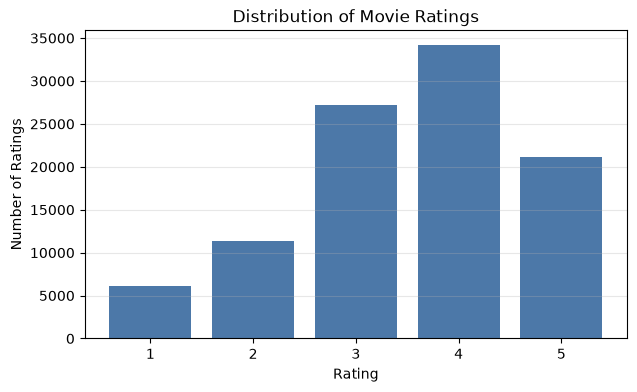

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


In [27]:
#the distribution of ratings of the input
rating_counts = ratings_df["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(rating_counts.index, rating_counts.values, color="#4C78A8")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)
plt.show()

print(rating_counts)

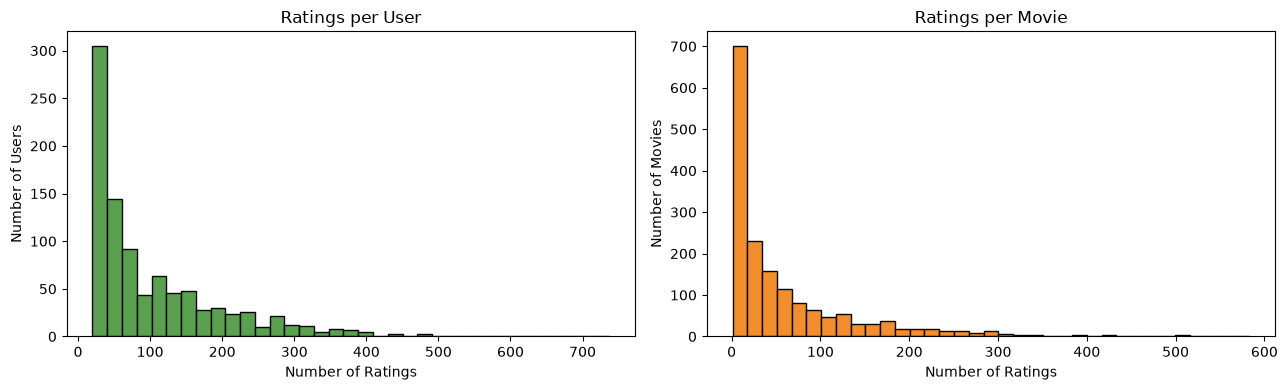

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
dtype: float64


In [28]:
# the number of ratings for each user and movie respectively
ratings_per_user = ratings_df.groupby("user_id").size()
ratings_per_movie = ratings_df.groupby("movie_id").size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(ratings_per_user, bins=35, color="#59A14F", edgecolor="black")
axes[0].set_title("Ratings per User")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Number of Users")

axes[1].hist(ratings_per_movie, bins=35, color="#F28E2B", edgecolor="black")
axes[1].set_title("Ratings per Movie")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

print(ratings_per_user.describe())

## THE TRAINED MODELS

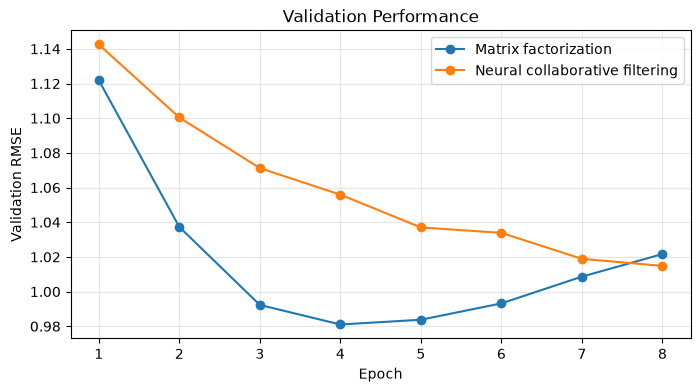

In [29]:
# comparison of the validation curves from matrix factorization and neural collaborative filtering models
plt.figure(figsize=(8, 4))
plt.plot(matrix_history["epoch"], matrix_history["validation_rmse"], marker="o", label="Matrix factorization")
plt.plot(neural_history["epoch"], neural_history["validation_rmse"], marker="o", label="Neural collaborative filtering")
plt.xlabel("Epoch")
plt.ylabel("Validation RMSE")
plt.title("Validation Performance")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

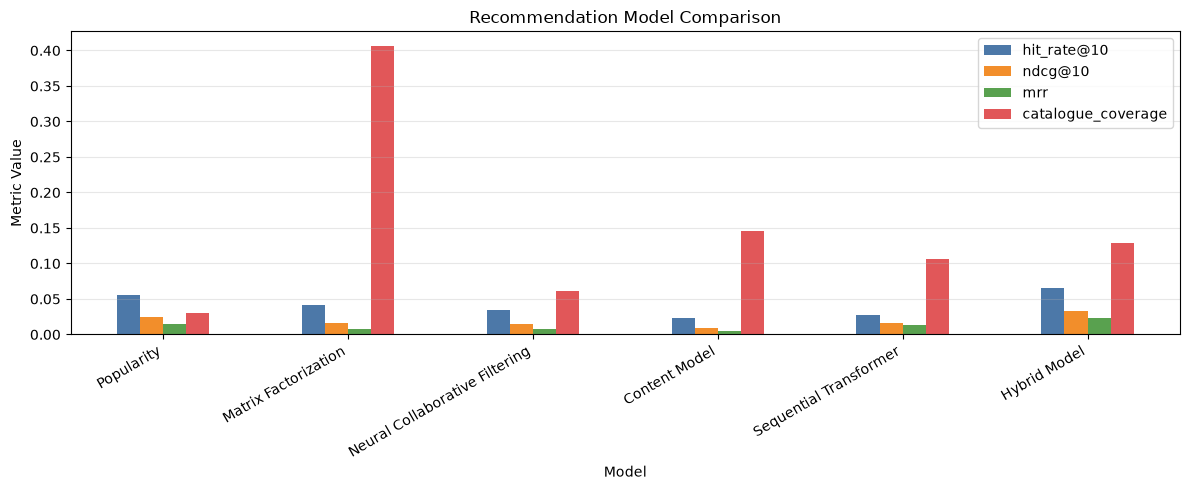

In [30]:
# plot the most important ranking metrics
metrics_to_plot = ["hit_rate@10", "ndcg@10", "mrr", "catalogue_coverage"]

evaluation_df[metrics_to_plot].plot( kind="bar", figsize=(12, 5), color=["#4C78A8", "#F28E2B", "#59A14F", "#E15759"] )

plt.title("Recommendation Model Comparison")
plt.xlabel("Model")
plt.ylabel("Metric Value")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()